1/clkgen_freq=125.0 ns phase_shift_steps=4200
ext_offset=3 (375 ns)  offset=0 (0 ps)  width=3360 (100 ns)  repeat=4 (pulse 500 ns)
computed start=865 ns   measured: delay=980 ns  pulse=509 ns  start diff=115 ns


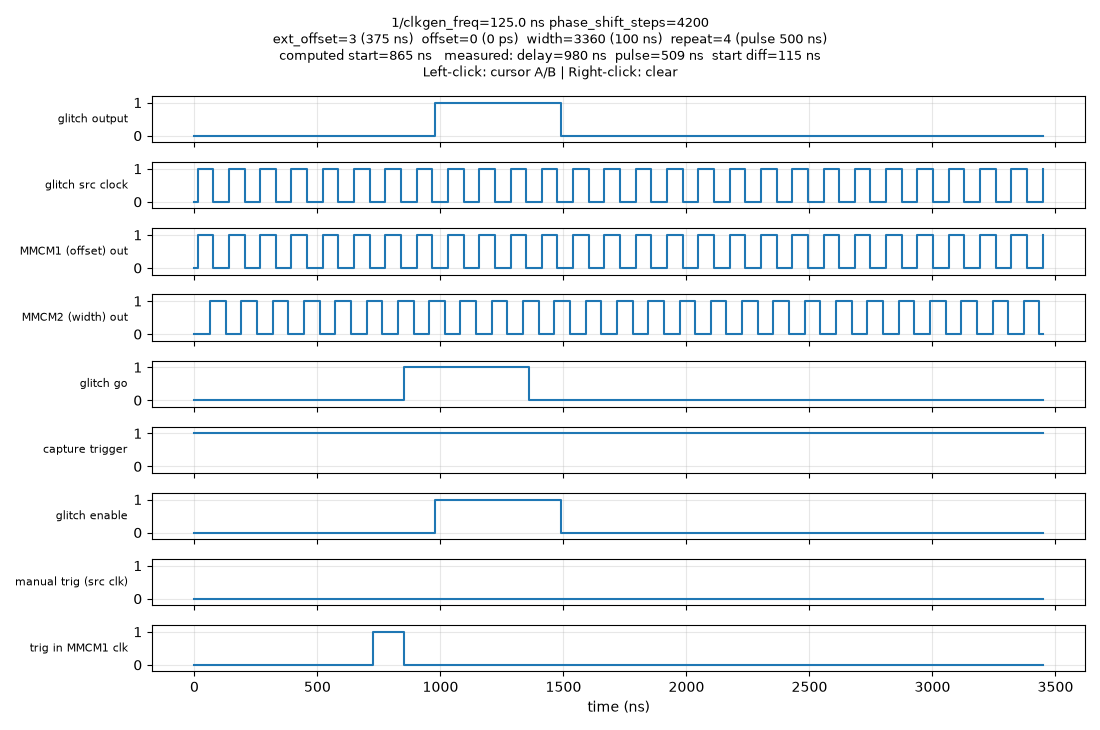

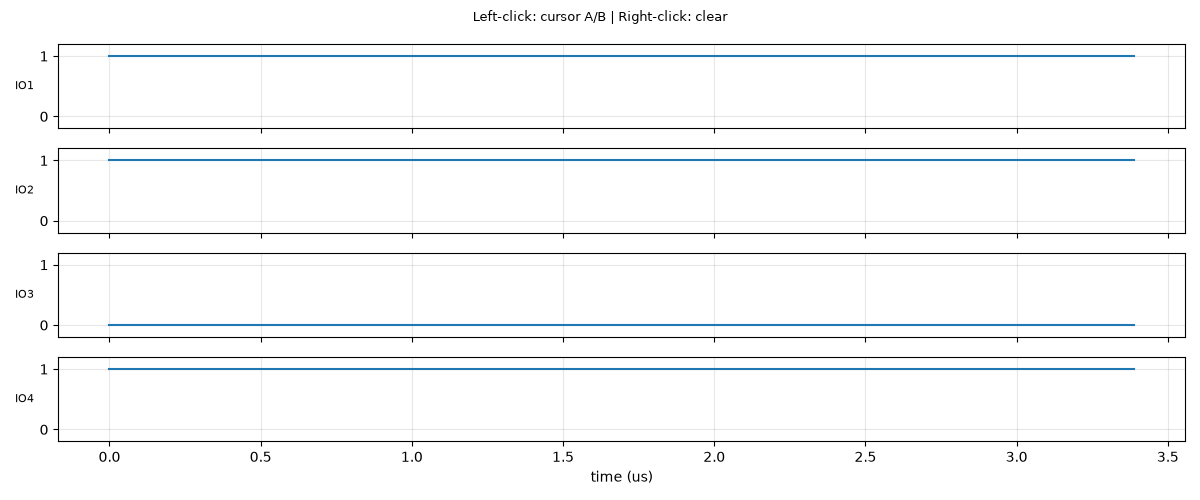

scope.glitch.clk_src  pll
scope.clock.clkgen_freq  8000000.0
scope.clock.fpga_vco_freq  600000000.0
scope.LA.sampling_clock_frequency  80001251.22070312
scope.LA.downsample  1
scope.glitch.phase_shift_steps  4200
ext_offset=1      pulses=1  delay=     752 ns  pulse=     127 ns
ext_offset=5      pulses=1  delay=    1350 ns  pulse=     127 ns
ext_offset=20     pulses=1  delay=    3124 ns  pulse=     126 ns
ext_offset=100    pulses=0  delay=     nan ns  pulse=     nan ns


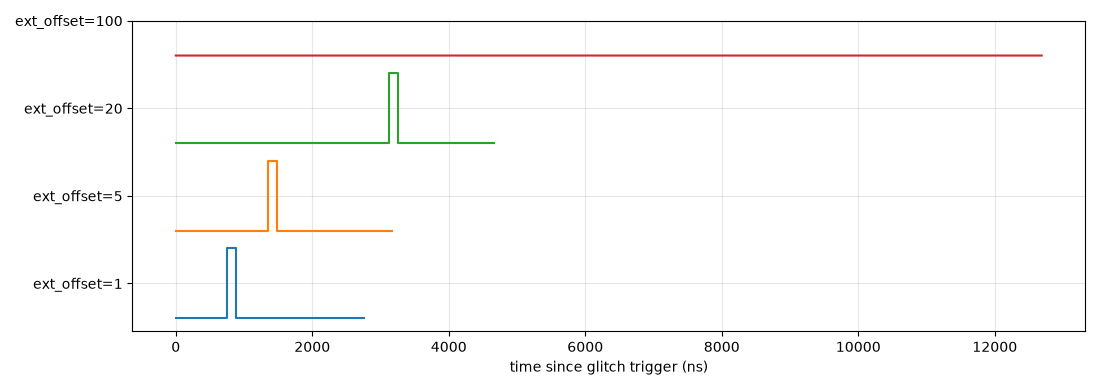

In [6]:
%run "./LibLogicAnalyserGlitchTools.ipynb"

def capture_with_la(group):
    scope.errors.clear()
        
    scope.LA.capture_group = group
    scope.io.glitch_trig_mcx = 'glitch' # Glitch pulse on the Trigger/Glitch Out MCX connector
    #scope.io.hs2 = 'glitch'  # Glitch on HS2, for example to feed an external device
    scope.io.hs2 = 
    pre_arm_action(scope)
    time.sleep(0.01)
    scope.LA.arm()                        
    post_arm_trigger_action(scope)
    time.sleep(0.003)
    post_capture_action(scope)
    
    raw = scope.LA.read_capture_data()
    sigs = {}
    for i in range(9):
        try:
            sigs[i] = scope.LA.extract(raw, i)
        except Exception:
            break

    scope.LA.enabled = False
    return sigs


def plot_interactive(sigs, time_axis, unit, snap=True, channels=None, group="CW 20-pin"):
    """
    channels: None -> all signals
              list of indices, e.g. [0, 1, 4]
              list of names,   e.g. ["IO1", "IO2", "HS1"]
              (order of the list = order of the rows in the plot)
    group:    key in LA_NAMES that provides the channel names
    """
    names = LA_NAMES[group]

    if channels is None:
        channels = list(range(min(len(names), len(sigs))))
    else:
        # convert names to indices, keep indices as they are
        channels = [names.index(c) if isinstance(c, str) else int(c)
                    for c in channels]
    labels = {i: names[i] for i in channels}

    fig, axes = plt.subplots(len(labels), 1,
                             figsize=(12, 1 + 1.0 * len(labels)),
                             sharex=True, squeeze=False)
    axs = axes[:, 0]

    edge_times = []
    for ax, (i, name) in zip(axs, labels.items()):
        sig = np.asarray(sigs[i])
        t = np.asarray(time_axis(sig, unit))
        ax.step(t, sig, where="post")
        ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
        ax.set_yticks([0, 1])
        ax.set_ylim(-0.2, 1.2)
        ax.grid(True, alpha=0.3)
        edge_times.append(t[np.flatnonzero(np.diff(sig) != 0) + 1])
    edges = np.sort(np.concatenate(edge_times))
    axs[-1].set_xlabel(f"time ({unit})")

    help_txt = "Left-click: cursor A/B | Right-click: clear"
    fig.suptitle(help_txt, fontsize=9)
    marks, lines = [], []

    def clear():
        for ln in lines:
            ln.remove()
        lines.clear()
        marks.clear()

    def on_click(event):
        tb = fig.canvas.toolbar
        if tb is not None and getattr(tb, "mode", "") != "":
            return                          # zoom/pan tool is active
        if event.inaxes not in axs:
            return
        if event.button == 3:               # right-click clears
            clear()
            fig.suptitle(help_txt, fontsize=9)
            fig.canvas.draw_idle()
            return
        if event.button != 1:
            return

        x = event.xdata
        if snap and edges.size:
            x = edges[np.argmin(np.abs(edges - x))]
        if len(marks) == 2:
            clear()
        marks.append(x)
        color = "tab:red" if len(marks) == 1 else "tab:green"
        for ax in axs:
            lines.append(ax.axvline(x, color=color, linestyle="--", lw=1))

        if len(marks) == 1:
            msg = f"A = {x:.4g} {unit}"
        else:
            dt = abs(marks[1] - marks[0])
            msg = (f"A = {marks[0]:.4g} {unit}   B = {marks[1]:.4g} {unit}   "
                   f"Δt = {dt:.4g} {unit}")
        fig.suptitle(msg, fontsize=10)
        fig.canvas.draw_idle()

    fig.canvas.mpl_connect("button_press_event", on_click)
    fig.tight_layout()
    plt.show()
    return fig


    

import chipwhisperer as cw

try:
    scope.dis()
except:
    pass
try:
    fig.dis()
except:
    pass
try:
    fig1.dis()
except:
    pass

scope = cw.scope()
scope.default_setup(verbose=False)
scope.clock.clkgen_freq = 8e6

scope.io.tio1 = "high_z"
scope.io.tio2 = "high_z"
scope.io.tio3 = "high_z"
scope.io.tio4 = "gpio_low"


#sweep(scope, "ext_offset", [1, 5, 20, 100])          # delay should grow ~100 ns per count
#sweep(scope, "repeat", [1, 2, 5, 10], ext_offset=5)  # pulse length in clock cycles
# one run with all 9 channels, using the interactive plot
ext_offset = 3
width = 3360
offset = 0
repeat = 4
output="enable_only"  # one large glitch repeat times
#output="glitch_only" # multiple short (width) glitches
res = run_glitch(scope, ext_offset=ext_offset, width=width, repeat=repeat, offset=offset, output=output, f_glitch=scope.clock.clkgen_freq)

print(caption(res))
fig = plot_la_interactive(res["t"] * 1e9, res["sigs"], LA_NAMES["glitch"], unit="ns", title=caption(res))

sigs2 = capture_with_la('CW 20-pin')
f_la = scope.LA.sampling_clock_frequency / scope.LA.downsample
time_axis = make_time_axis(f_la)
unit = 'us'
fig1 = plot_interactive(sigs2, time_axis, unit, snap=True, channels=["IO1", "IO2", "IO3", "IO4"])


print("scope.glitch.clk_src ", scope.glitch.clk_src)
print("scope.clock.clkgen_freq ", scope.clock.clkgen_freq)
print("scope.clock.fpga_vco_freq ", scope.clock.fpga_vco_freq)
print("scope.LA.sampling_clock_frequency ", scope.LA.sampling_clock_frequency)
print("scope.LA.downsample ", scope.LA.downsample)
print("scope.glitch.phase_shift_steps ", scope.glitch.phase_shift_steps)
sweep(scope, "ext_offset", [1, 5, 20, 100])   # ns per count = real period on the plot axis

scope.dis()
scope=None